In [1]:
import os
import sys

current_path = os.path.abspath(os.getcwd())
base_path = os.path.abspath(os.path.join(current_path, '../../../'))
dfield_approach_elastix_path = os.path.abspath(os.path.join(current_path, '../'))
sys.path.append(base_path)
sys.path.append(dfield_approach_elastix_path)

import numpy as np
import matplotlib.pyplot as plt  
import pandas as pd
from tqdm import tqdm
import pandas as pd
from IPython.display import display


import project_images_loader as pil
import utils.util as util
import utils.functions as fc
import utils.nifti_functions as nfc

import constants as cts
import dfield_applier as dfield_applier




In [2]:

def get_img_all_data_you_need(id, simple_mask=True):
    img_moving_path_name = pil.get_registered_to_template_image_path_name(3, id, pil.REGISTRATION_TO_MNI, absolute=True)
    mask_moving_path_name = pil.get_segmentation_path_name(3, id, simple=simple_mask, absolute=True)

    dfield_path_name = cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_DFIELD)

    # load images and masks
    img_moving, aff_moving = nfc.load_nifti(img_moving_path_name)
    mask_moving, _ = nfc.load_nifti(mask_moving_path_name)

    img_fixed, _ = nfc.load_nifti(pil.get_registered_to_template_image_path_name(4, id, pil.REGISTRATION_TO_MNI, absolute=True))
    mask_fixed, _ = nfc.load_nifti(pil.get_segmentation_path_name(4, id, simple=simple_mask, absolute=True))

    img_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_REGISTERED))
    if simple_mask:
        mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_SIMPLE_REGISTERED))
    else:
        mask_registed, _ = nfc.load_nifti(cts.get_image_path_name(id, cts.PFILE_0038, cts.INAME_SEG_REGISTERED))

    img_moving = util.skull_stripping_and_normalize(img_moving, mask_moving) 
    img_fixed = util.skull_stripping_and_normalize(img_fixed, mask_fixed) 
    img_registed = util.skull_stripping_and_normalize(img_registed, mask_registed)

    # img_reg_elastix = dfield_applier.apply_deformation_field_elastix(img_moving_path_name, dfield_path_name)
    # mask_reg_elastix = dfield_applier.apply_deformation_field_elastix(mask_moving_path_name, dfield_path_name, binary=True)
    # img_reg_elastix = util.skull_stripping_and_normalize(img_reg_elastix, mask_reg_elastix)

    metrisc_original = util.get_metrics_dict(img_moving, img_fixed)
    metrisc_expected = util.get_metrics_dict(img_registed, img_fixed)
    # metrisc_base = util.get_metrics_dict(img_reg_elastix, img_fixed)

    dice_original = util.compute_multiple_dice_coefficients(mask_moving, mask_fixed)
    dice_expected = util.compute_multiple_dice_coefficients(mask_registed, mask_fixed)


    metrics_list = [metrisc_original, metrisc_expected]
    dices_list = [dice_original, dice_expected]


    return  (img_moving_path_name, mask_moving_path_name, dfield_path_name), ((img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)), metrics_list, dices_list, aff_moving


### Compute metrics

In [3]:

# valid_mean_dfields = [10, 100, 200]
# valid_mean_dfields = [100]
valid_mean_dfields = [10, 100, 200, 300]
matchin_ids = pil.get_matching_ids()
# id_indexs = [301,302,303,304,305,306,307]
id_indexs = [301,302,303,304,305]
# id_indexs = [301]
# id_indexs = [0, 11, 101, 301,302,303,304]
df_first_columns = list(('ORG', 'EXP') + tuple(["{0:03}".format(d) for d in valid_mean_dfields]))

imgs_list = []
ordered_index_imgs = []
ordered_index_segs = []

for id_index in id_indexs:
    id_target = matchin_ids[id_index]

    print(f"ID: {id_index}: {id_target}")
    (img_moving_path_name, mask_moving_path_name, dfield_path_name), ((img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)), metrics_list, dices_list, aff_moving = get_img_all_data_you_need(id_target, simple_mask=False)
    
    imgs = [(img_fixed, mask_fixed), (img_moving, mask_moving), (img_registed, mask_registed)]
    for valid_mean_dfield in valid_mean_dfields:
        mean_dfield_path_name = cts.get_mean_dfield_path_name(cts.PFILE_0038, valid_mean_dfield)
        
        _img_reg = dfield_applier.apply_deformation_field_elastix(img_moving_path_name, mean_dfield_path_name)
        _mask_reg = dfield_applier.apply_deformation_field_elastix(mask_moving_path_name, mean_dfield_path_name, binary=True)

        _img_reg_to_save = _img_reg.copy()
        _img_reg = util.skull_stripping_and_normalize(_img_reg, _mask_reg)

        metrics_list.append(util.get_metrics_dict(_img_reg, img_fixed))
        dices_list.append(util.compute_multiple_dice_coefficients(_mask_reg, mask_fixed))

        imgs.append((_img_reg, _mask_reg))

        # save images
        dir_name = os.path.dirname(mean_dfield_path_name) + '/imgs_results'
        reg_img_path_name = f"{dir_name}/{id_target}_REG_T1_{valid_mean_dfield}.nii.gz"
        reg_seg_path_name = f"{dir_name}/{id_target}_REG_SEG_{valid_mean_dfield}.nii.gz"
        nfc.save_nifti(_img_reg_to_save, aff_moving, reg_img_path_name)
        nfc.save_nifti(_mask_reg, aff_moving, reg_seg_path_name)

    imgs_list.append(imgs)


    # print image metrics
    df_metrics = pd.DataFrame(metrics_list)
    df_metrics.insert(0, 'VALUES', df_first_columns)
    df_metrics = df_metrics.sort_values(by=df_metrics.columns[-1], ascending=False)
    display(df_metrics.head(10))

    ordered_index_img = df_metrics.index.to_list()
    ordered_index_img = [idx for idx in ordered_index_img if idx != 0 and idx != 1]
    ordered_index_imgs.append(ordered_index_img)


    #  print segmentation metrics
    df_dices = pd.DataFrame(dices_list)
    df_dices_stats = pd.DataFrame({
        'min': df_dices.min(axis=1),
        'max': df_dices.max(axis=1),
        'mean': df_dices.mean(axis=1)
    })
    df_dices_stats.insert(0, 'VALUES', df_first_columns)
    df_dices_stats = df_dices_stats.sort_values(by=df_dices_stats.columns[-1], ascending=False)

    ordered_index_seg = df_dices_stats.index.to_list()
    ordered_index_seg = [idx for idx in ordered_index_seg if idx != 0 and idx != 1]
    ordered_index_segs.append(ordered_index_seg)
    
    display(df_dices_stats.head(10))
    



ID: 301: 08189


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000032,0.988434,0.973252,0.969948
3,100,0.000045,0.962399,0.858696,0.956307
5,300,0.000046,0.960647,0.857954,0.956268
4,200,0.000047,0.960788,0.856945,0.956079
2,010,0.000051,0.957783,0.844326,0.953612
0,ORG,0.000065,0.912206,0.805449,0.947091


,VALUES,min,max,mean
1,EXP,0.598085,0.994130,0.864369
3,100,0.319313,0.992451,0.826910
5,300,0.266317,0.992498,0.825845
4,200,0.277379,0.992470,0.825790
2,010,0.366639,0.992093,0.818578
0,ORG,0.013686,0.992093,0.805837


ID: 302: 08202


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000028,0.985230,0.841844,0.974578
5,300,0.000048,0.946430,0.736065,0.962789
4,200,0.000048,0.945597,0.735008,0.962670
3,100,0.000049,0.943619,0.733276,0.962415
2,010,0.000051,0.941710,0.726493,0.960313
0,ORG,0.000060,0.919692,0.698001,0.956920


...

,VALUES,rms,ncc,mi,ssim
1,EXP,0.000027,0.986390,0.863341,0.971361
4,200,0.000047,0.954689,0.755893,0.957456
5,300,0.000048,0.952907,0.753844,0.957255
3,100,0.000047,0.955291,0.754405,0.956908
2,010,0.000051,0.949556,0.739573,0.952181
0,ORG,0.000070,0.899514,0.704628,0.946186


,VALUES,min,max,mean
1,EXP,0.607008,0.994546,0.854836
4,200,0.494382,0.992840,0.812265
5,300,0.467797,0.992829,0.811407
3,100,0.512605,0.992740,0.810217
2,010,0.536518,0.992177,0.803740
0,ORG,0.056666,0.991941,0.782981


ID: 305: 08295


,VALUES,rms,ncc,mi,ssim
1,EXP,0.000027,0.987096,1.054554,0.966671
5,300,0.000079,0.870585,0.813186,0.926725
4,200,0.000080,0.869564,0.813007,0.926439
3,100,0.000080,0.870267,0.812491,0.926137
2,010,0.000082,0.861129,0.802480,0.922750
0,ORG,0.000087,0.835656,0.782401,0.917967


,VALUES,min,max,mean
1,EXP,0.645170,0.993605,0.859475
5,300,0.096788,0.988796,0.766249
3,100,0.113479,0.988717,0.766097
4,200,0.098601,0.988791,0.765980
2,010,0.120515,0.988273,0.755207
0,ORG,0.016901,0.987782,0.744745


ID: 301: 08189


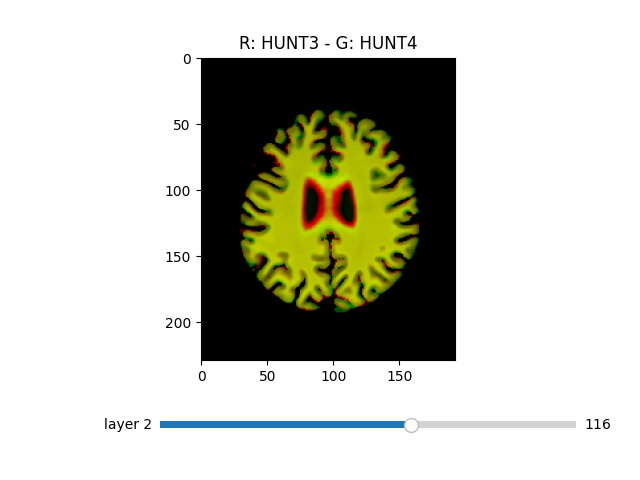

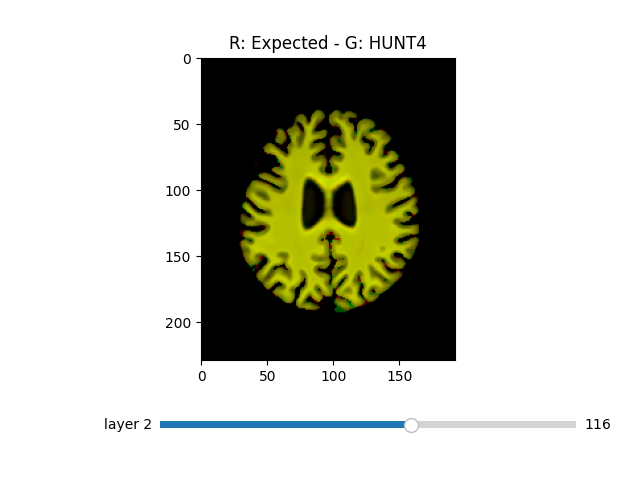

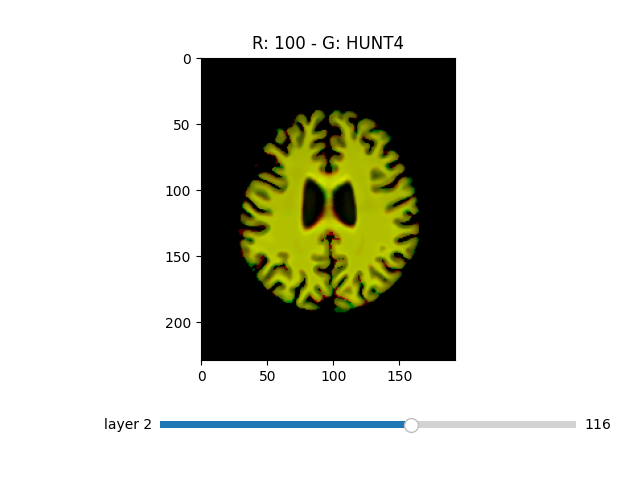

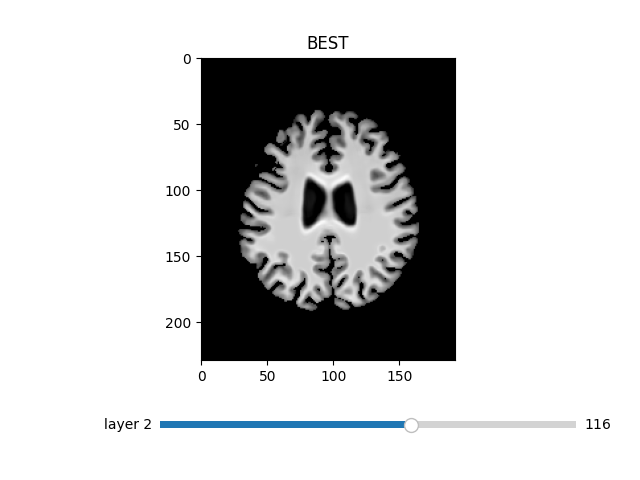

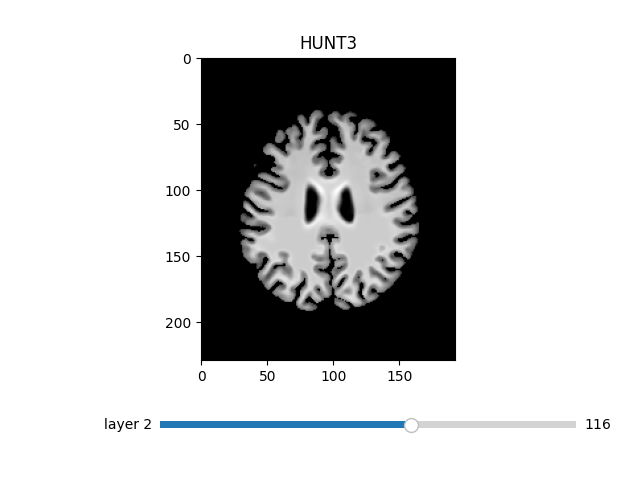

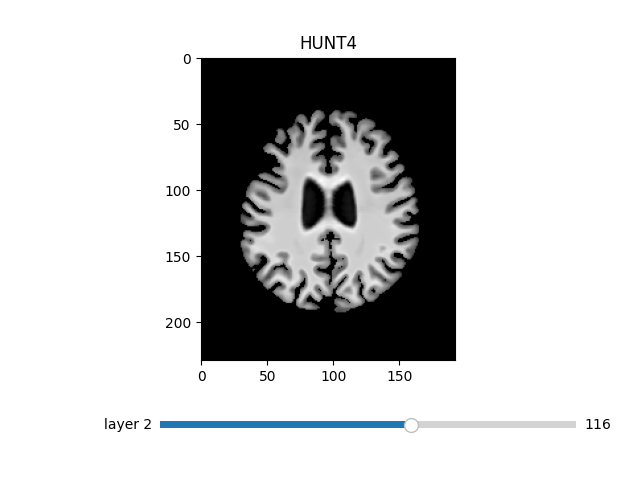

ID: 302: 08202


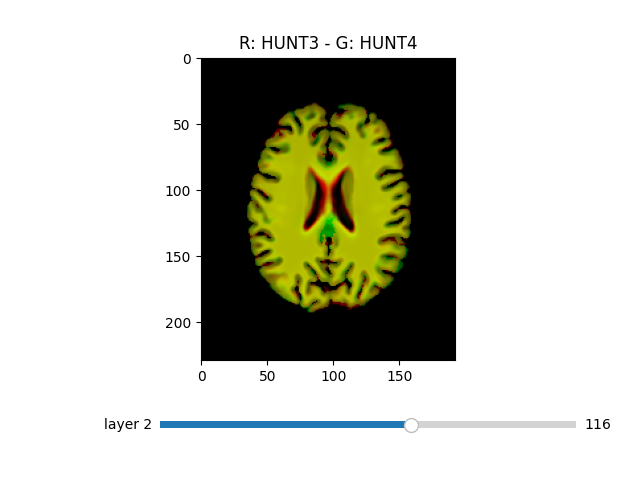

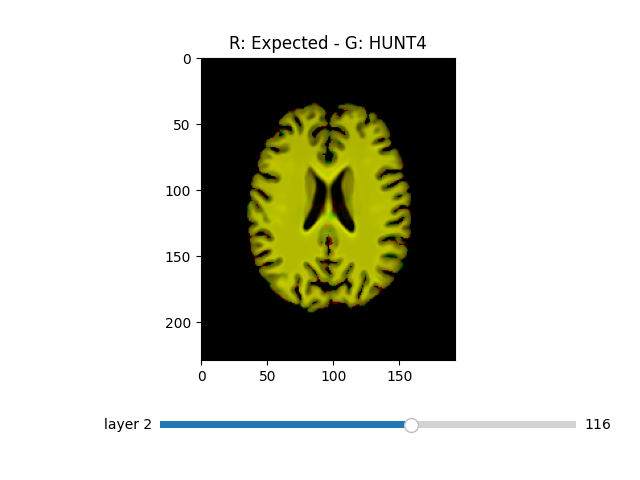

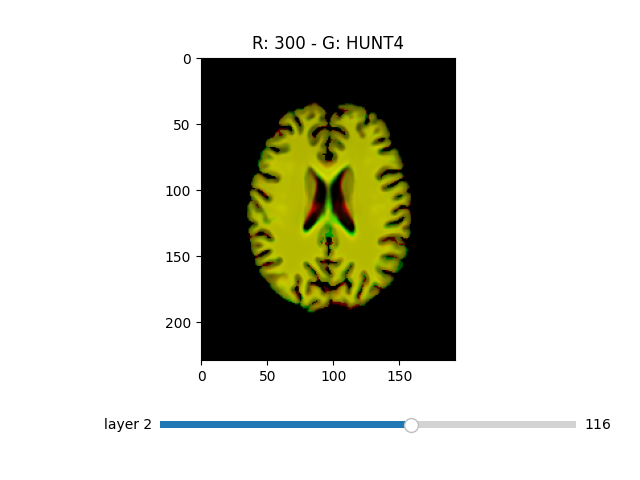

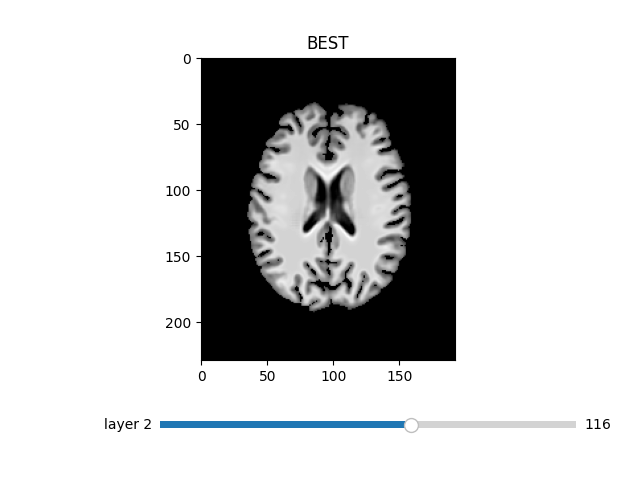

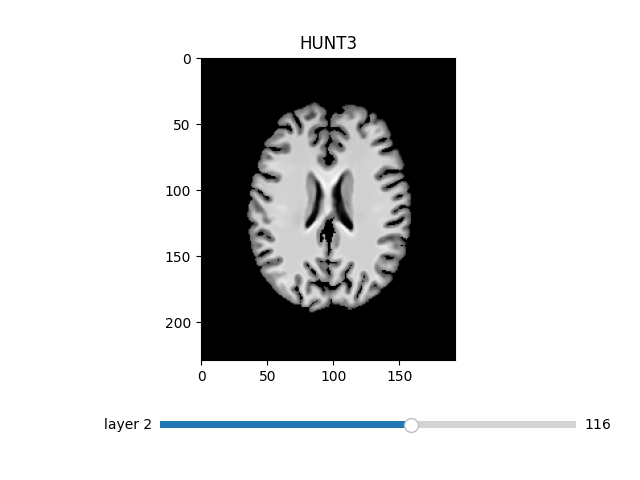

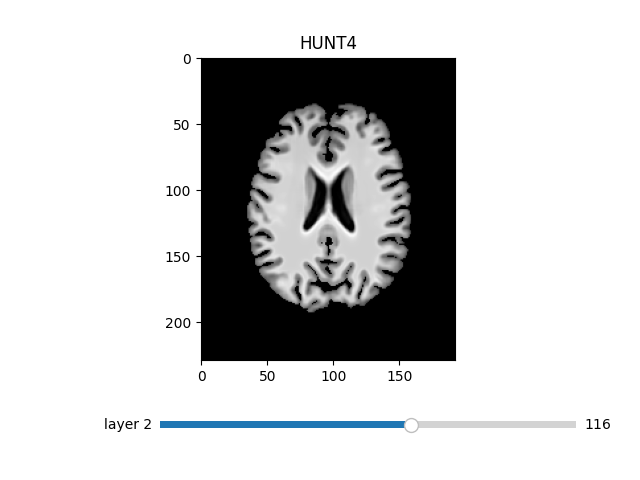

ID: 303: 08264


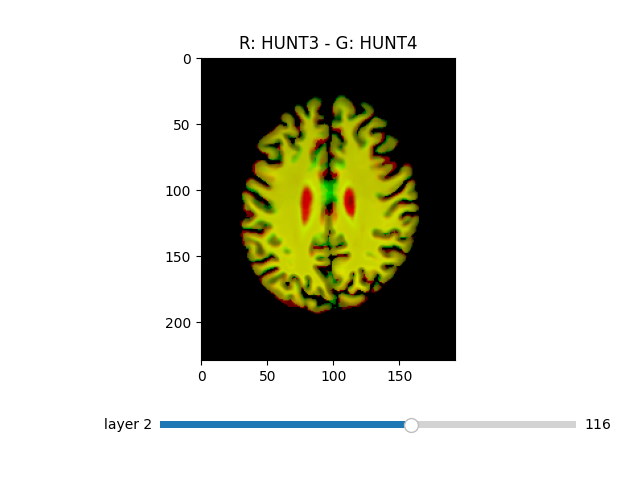

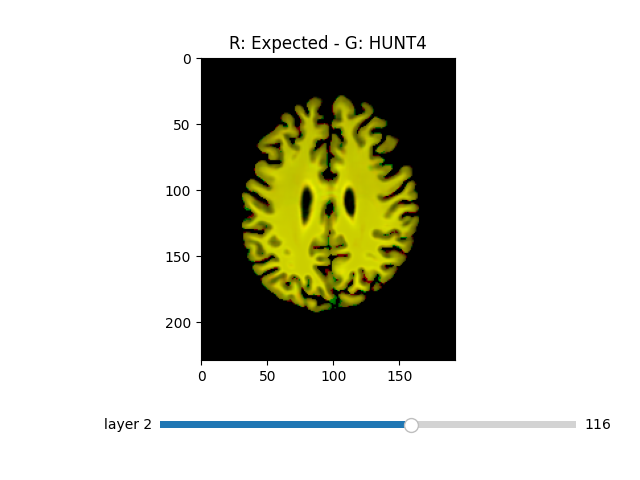

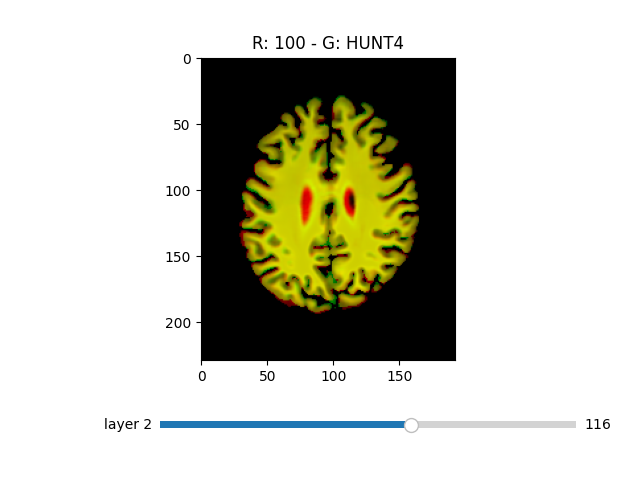

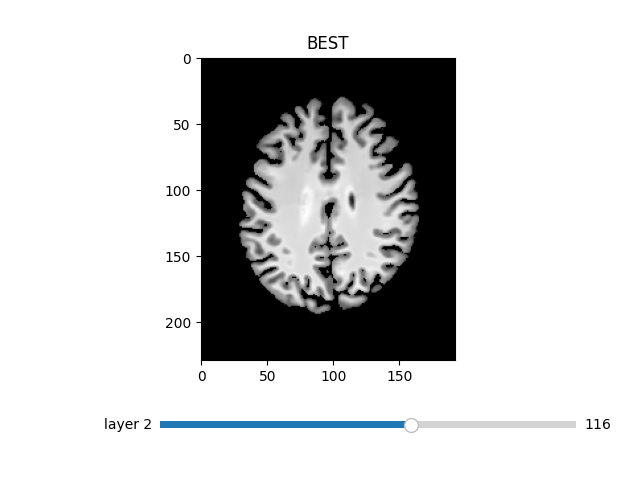

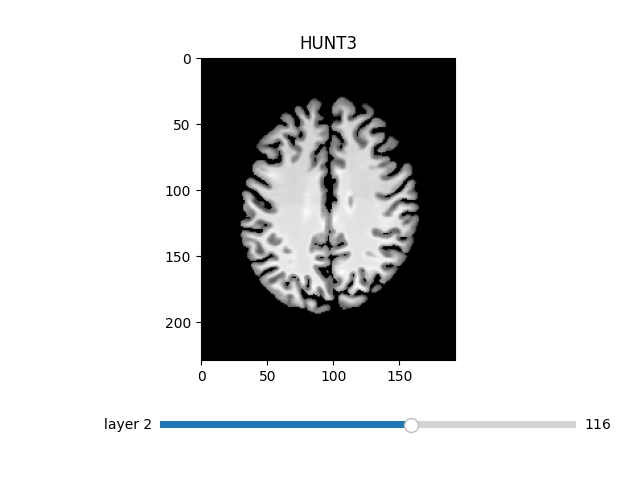

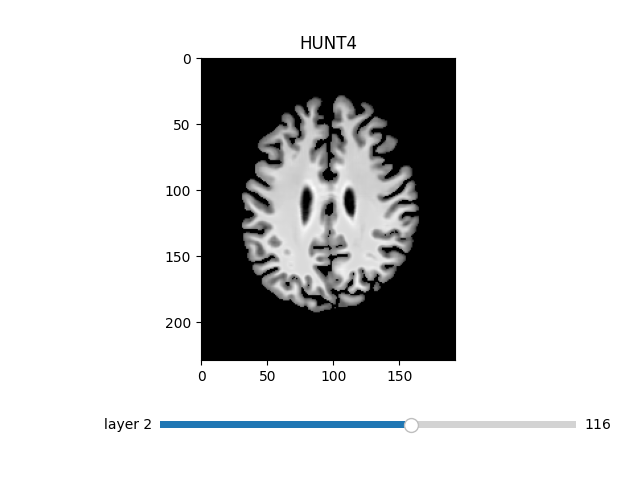

ID: 304: 08271


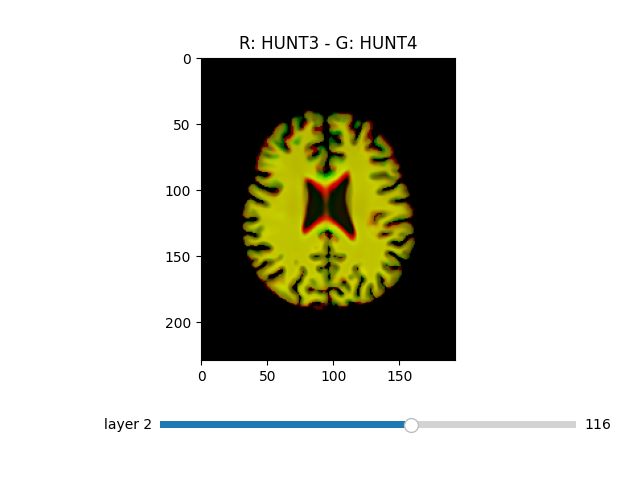

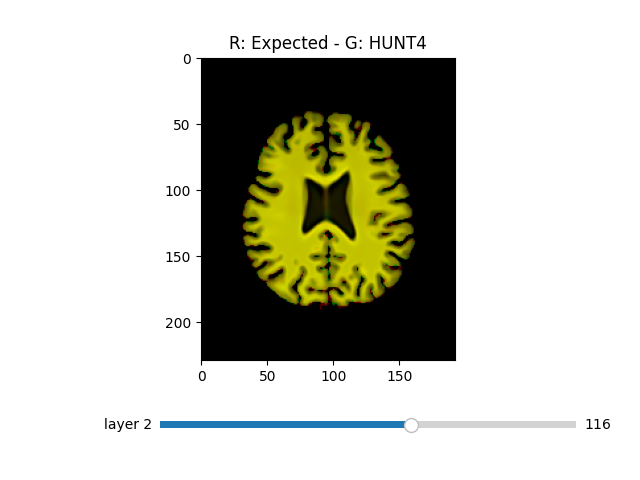

More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.


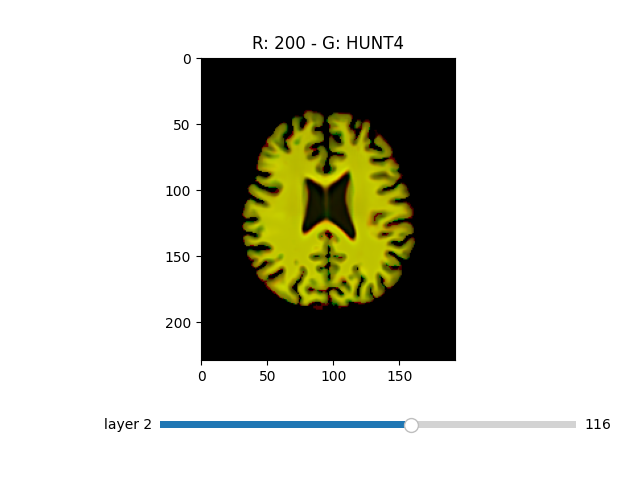

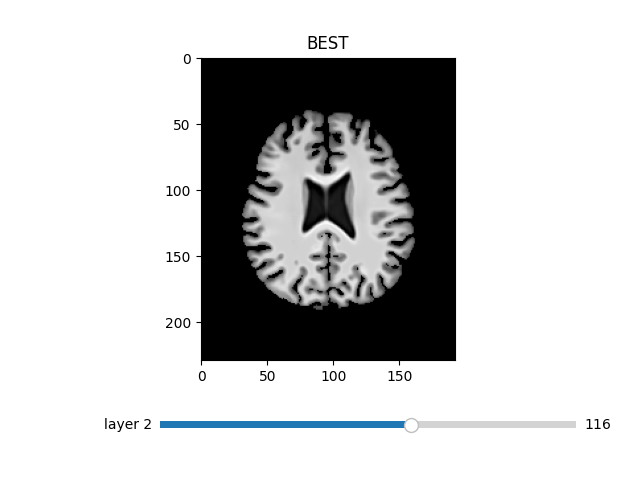

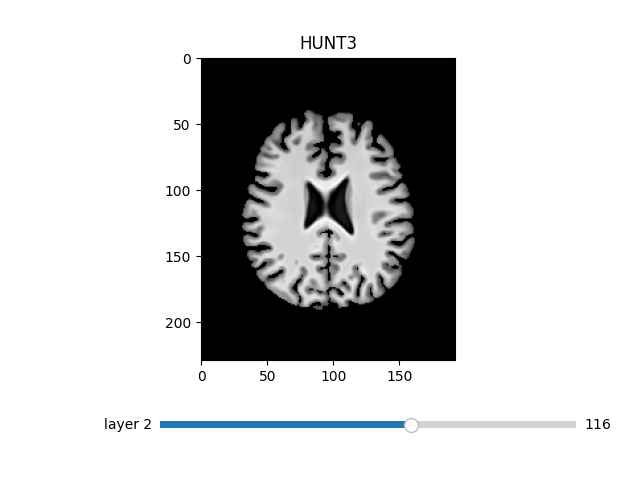

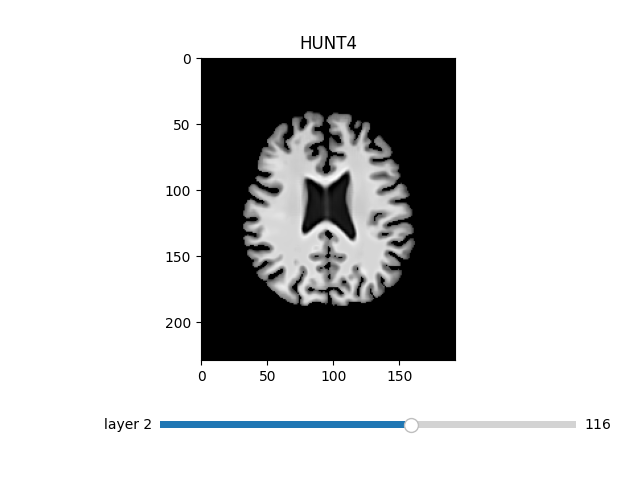

ID: 305: 08295


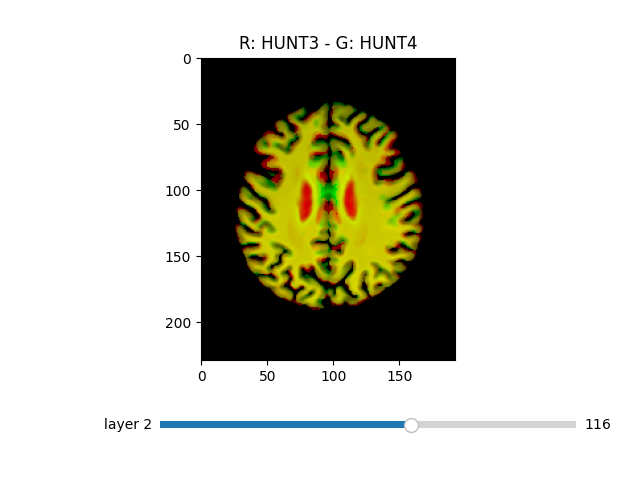

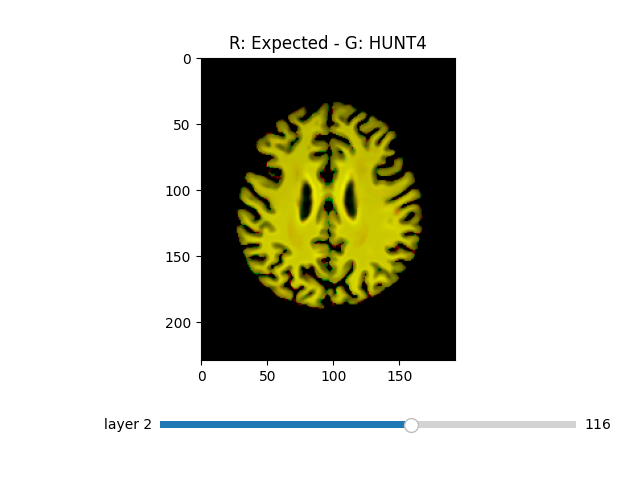

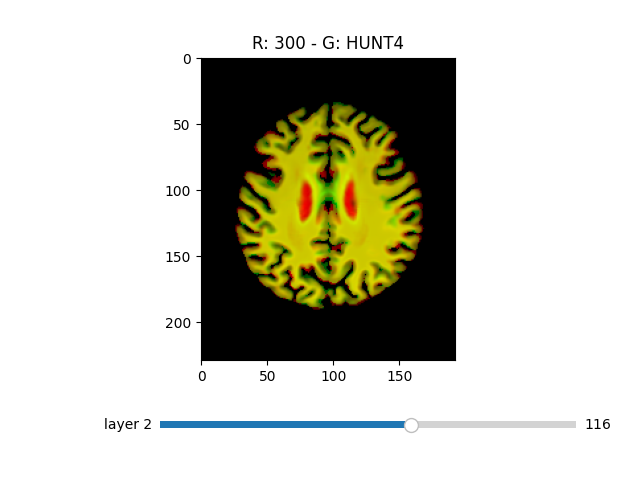

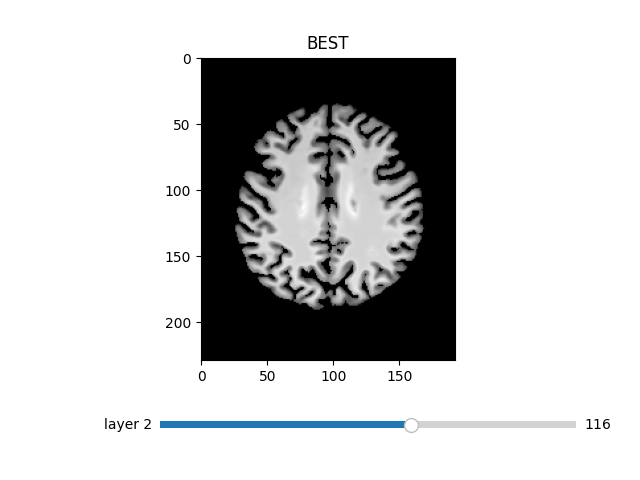

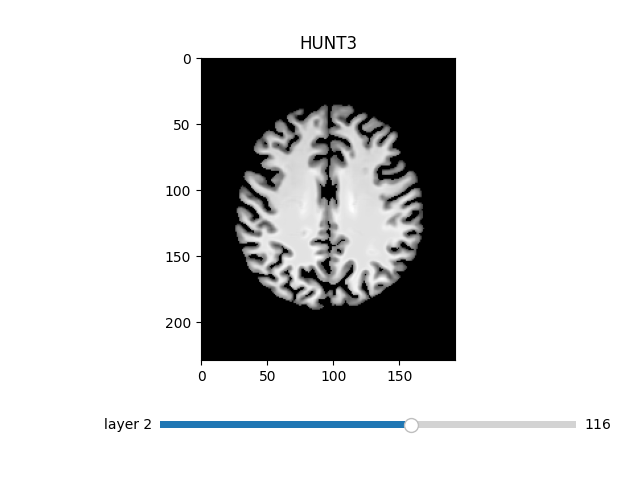

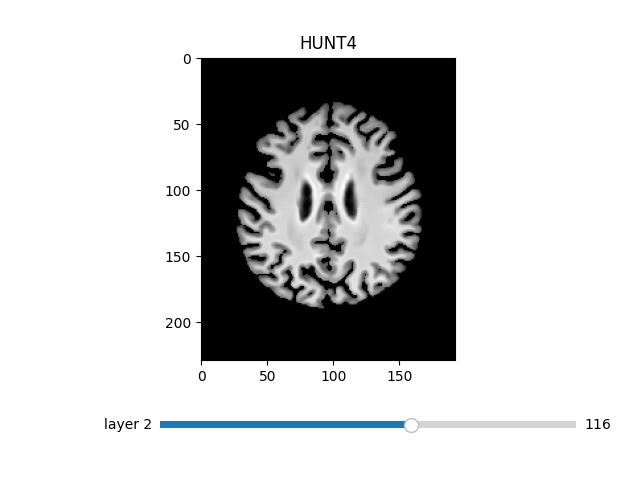

In [4]:
current_plane = 116
def shows_rgb_img(img_fixed, img_reg, name=""):
    img_rgb = np.stack((img_reg, img_fixed, np.zeros_like(img_fixed)), axis=3)
    fc.imgshow_3D(name, img_rgb, current_plane=current_plane, transpose=True, flip_ax=0)
    return img_rgb

%matplotlib widget
for id_index, imgs in enumerate(imgs_list):
    print(f"ID: {id_indexs[id_index]}: {matchin_ids[id_indexs[id_index]]}")

    img_fixed, mask_fixed = imgs[0]
    img_moving, mask_moving = imgs[1]
    img_expected, mask_expected = imgs[2]
    shows_rgb_img(img_fixed, img_moving, "R: HUNT3 - G: HUNT4")
    shows_rgb_img(img_fixed, img_expected, "R: Expected - G: HUNT4")
    # for i, (img, mask) in enumerate(imgs[3:]):
    for i in [ordered_index_imgs[id_index][0]]:
        img, mask = imgs[i]
        img_rgb = shows_rgb_img(img_fixed, img, f"R: {df_first_columns[i]} - G: HUNT4")

        # # save rgb image
        # dir_name = 'C:/Users/Agustin/Master/Master/S4/code/test_code/dfield_approach_elastix/images/image_rgb_best_results'
        # img_name = f'{matchin_ids[id_indexs[id_index]]}_MEAN_DFIELD.nii.gz'
        fc.imgshow_3D("BEST", img, current_plane=current_plane, transpose=True, flip_ax=0)

    fc.imgshow_3D("HUNT3", img_moving, current_plane=current_plane, transpose=True, flip_ax=0)
    fc.imgshow_3D("HUNT4", img_fixed, current_plane=current_plane, transpose=True, flip_ax=0)


In [13]:
import utils.util_freesurfer_segmentation as util_freesurfer

def show_overlap_rgb_seg(seg_fixed, seg_reg, name=""):
    seg_fixed_rgb = util_freesurfer.seg_to_rgbseg(seg_fixed).astype(np.float32)
    seg_reg_rgb = util_freesurfer.seg_to_rgbseg(seg_reg).astype(np.float32)

    overlap_original = ((seg_fixed_rgb + seg_reg_rgb) / 2).astype(np.uint8)
    fc.imgshow_3D(name, overlap_original, current_plane=118, transpose=True, flip_ax=0)


%matplotlib widget
for id_index, imgs in enumerate(imgs_list[:2]):
    print(f"ID: {id_indexs[id_index]}: {matchin_ids[id_indexs[id_index]]}")

    img_fixed, mask_fixed = imgs[0]
    img_moving, mask_moving = imgs[1]
    img_expected, mask_expected = imgs[2]
    show_overlap_rgb_seg(mask_fixed, mask_moving, "HUNT3 - HUNT4")
    show_overlap_rgb_seg(mask_fixed, mask_expected, "Expected - HUNT4")
    # for i, (img, mask) in enumerate(imgs[3:]):
    for i in ordered_index_seg[id_index]:
        img, mask = imgs[i]
        show_overlap_rgb_seg(mask_fixed, mask, f"{df_first_columns[i]} - HUNT4")
        


ID: 301: 08189


# Chat evaluation

First, let's calculate the means and standard deviations for each registration method and each metric. Then, we will rank the methods based on these metrics.

**Means:**

- EXP: 
  - NCC: 0.983448
  - SSIM: 0.9180
  - Minimum DICE: 0.7813
  - Maximum DICE: 0.8328
  - Mean DICE: 0.8092

- 100: 
  - NCC: 0.9423
  - SSIM: 0.8388
  - Minimum DICE: 0.5173
  - Maximum DICE: 0.8500
  - Mean DICE: 0.7953

- 200: 
  - NCC: 0.9209
  - SSIM: 0.7993
  - Minimum DICE: 0.4570
  - Maximum DICE: 0.8462
  - Mean DICE: 0.7865

- 010: 
  - NCC: 0.9284
  - SSIM: 0.7982
  - Minimum DICE: 0.4921
  - Maximum DICE: 0.8384
  - Mean DICE: 0.7862

**Standard Deviations:**

- EXP: 
  - NCC: 0.0334
  - SSIM: 0.0146
  - Minimum DICE: 0.1017
  - Maximum DICE: 0.0067
  - Mean DICE: 0.0255

- 100: 
  - NCC: 0.0312
  - SSIM: 0.0638
  - Minimum DICE: 0.1256
  - Maximum DICE: 0.0117
  - Mean DICE: 0.0219

- 200: 
  - NCC: 0.0271
  - SSIM: 0.0711
  - Minimum DICE: 0.1213
  - Maximum DICE: 0.0138
  - Mean DICE: 0.0211

- 010: 
  - NCC: 0.0271
  - SSIM: 0.0723
  - Minimum DICE: 0.1213
  - Maximum DICE: 0.0138
  - Mean DICE: 0.0211

Now, let's rank them based on these metrics:

1. EXP
2. 100
3. 200
4. 010

In this ranking, the "EXP" method scores the highest in all metrics, followed by "100," "200," and "010" in descending order. This indicates that "EXP" is the best registration method among the four mentioned.